# Interface hotspots: nanobody-target complex

Step-by-step breakdown of `interface_hotspots.py`, with a plot after each step.

1. Load the structure and clean it (protein, heavy atoms)
2. Split target / nanobody chains
3. Contacts: any heavy atom within 4.5 A
4. Collapse to residues, split side-chain vs backbone contacts
5. Wider CB-based (10 A) definition
6. Buried SASA = SASA(target alone) - SASA(target in complex)
7. Ranked report and structure view

## 0. Parameters

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import biotite.structure as struc
import biotite.structure.io as strucio
import biotite.structure.io.pdbx as pdbx

STRUCTURE = '1G8-PTRAMP-CSS.pdb'   # .cif or .pdb
TARGET_CHAIN = 'A'                 # target chain
NB_CHAIN = 'C'                     # nanobody chain (B/E are ~22-residue chains; C/F are nanobody-sized)
DROP_CHAINS = ['D', 'E', 'F']   # second copy in the crystal dimer (crystal-packing contacts)
KEEP_GLYCANS = True   # keep carbohydrate residues (any glycan, detected by biotite); other non-protein atoms are dropped
HEAVY_CUTOFF = 4.5   # A, any-heavy-atom contact
CB_CUTOFF = 10.0     # A, RFdiffusion training definition

C_TGT, C_NB = '#1f77b4', '#d95f02'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Load the structure

For CIF, `use_author_fields=False` gives `label_seq_id` / `label_asym_id`, the numbering RFD4 selection strings use. Set it to `True` to match PyMOL. PDB files only carry author numbering.

Plot: CA trace of each kept chain, and atom counts per chain split into protein, glycan, other non-protein (waters, ions, ligands) and hydrogen. Chains in `DROP_CHAINS` are excluded from this plot.

atoms: 6622 | chains: ['A' 'B' 'C' 'D' 'E' 'F']


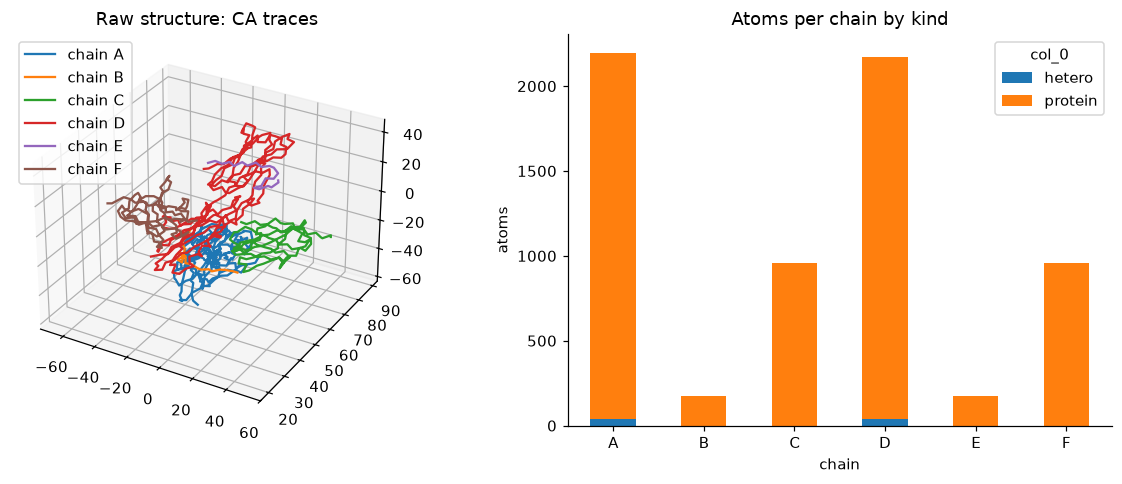

In [2]:
if STRUCTURE.endswith('.cif'):
    block = pdbx.CIFFile.read(STRUCTURE)
    raw = pdbx.get_structure(block, model=1, use_author_fields=False)
else:
    raw = strucio.load_structure(STRUCTURE, model=1)
print('atoms in file:', raw.array_length(), '| chains:', np.unique(raw.chain_id))

# chains listed in DROP_CHAINS are left out of this plot (and removed again in step 2)
shown = raw[~np.isin(raw.chain_id, DROP_CHAINS)]

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
palette = plt.cm.tab10.colors
for k, ch in enumerate(np.unique(shown.chain_id)):
    ca = shown[(shown.chain_id == ch) & (shown.atom_name == 'CA') & struc.filter_amino_acids(shown)]
    ax.plot(*ca.coord.T, color=palette[k % 10], lw=1.5, label=f'chain {ch}')
ax.set_title(f'CA traces (dropped: {", ".join(DROP_CHAINS) or "none"})'); ax.legend()

ax2 = fig.add_subplot(1, 2, 2)
kind = np.select(
    [shown.element == 'H', struc.filter_amino_acids(shown), struc.filter_carbohydrates(shown)],
    ['hydrogen', 'protein', 'glycan'],
    default='other non-protein',     # waters, ions, ligands
)
order = ['protein', 'glycan', 'other non-protein', 'hydrogen']
df = pd.crosstab(shown.chain_id, kind).reindex(columns=order, fill_value=0)
df.plot.bar(stacked=True, ax=ax2, rot=0, color=['#ff7f0e', '#2ca02c', '#1f77b4', '#bbbbbb'])
ax2.legend(title='atom kind')
ax2.set_title('Atoms per chain by kind'); ax2.set_xlabel('chain'); ax2.set_ylabel('atoms')
plt.tight_layout(); plt.show()

## 2. Clean and split chains

Keep amino acids plus glycans (`KEEP_GLYCANS`) (drops waters, ions, other ligands) and heavy atoms only, drop the chains listed in `DROP_CHAINS`, then build target / nanobody masks.

Plot: residue counts per chain and the two chains in colour.

In [ ]:
keep = struc.filter_amino_acids(raw)
if KEEP_GLYCANS:
    keep = keep | struc.filter_carbohydrates(raw)
arr = raw[keep]
arr = arr[arr.element != 'H']
arr = arr[~np.isin(arr.chain_id, DROP_CHAINS)]   # remove the duplicate copy so it cannot occlude the target

tgt = arr.chain_id == TARGET_CHAIN
nb = arr.chain_id == NB_CHAIN
assert tgt.sum() and nb.sum(), 'check your chain IDs'
print(f'target atoms: {tgt.sum()}  nanobody atoms: {nb.sum()}')

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1)
n_res = [struc.get_residue_count(arr[tgt]), struc.get_residue_count(arr[nb])]
ax.bar([f'target ({TARGET_CHAIN})', f'nanobody ({NB_CHAIN})'], n_res, color=[C_TGT, C_NB])
for i, v in enumerate(n_res): ax.text(i, v, str(v), ha='center', va='bottom')
ax.set_ylabel('residues'); ax.set_title('Residues per chain')

ax3 = fig.add_subplot(1, 2, 2, projection='3d')
for mask, c, lab in [(tgt, C_TGT, 'target'), (nb, C_NB, 'nanobody')]:
    ca = arr[mask & (arr.atom_name == 'CA')]
    ax3.plot(*ca.coord.T, color=c, lw=1.8, label=lab)
ax3.set_title('Cleaned complex'); ax3.legend()
plt.tight_layout(); plt.show()

## 3. Step 1a: atom-level contacts (4.5 A)

A `CellList` of nanobody atoms is queried with every target atom. `hits` holds nanobody atom indices within the radius, padded with `-1`.

Plot: distance from each target atom to its nearest nanobody atom (histogram with the cutoff), and the contacting target atoms in 3D.

In [ ]:
tgt_arr, nb_arr = arr[tgt], arr[nb]

cell = struc.CellList(nb_arr, cell_size=HEAVY_CUTOFF)
hits = cell.get_atoms(tgt_arr.coord, radius=HEAVY_CUTOFF)
atom_in_contact = (hits != -1).any(axis=1)
print(f'target atoms in contact: {atom_in_contact.sum()} / {len(atom_in_contact)}')

# nearest-neighbour distance for the plot (brute force, fine for one complex)
d = np.linalg.norm(tgt_arr.coord[:, None, :] - nb_arr.coord[None, :, :], axis=-1)
nearest = d.min(axis=1)

fig = plt.figure(figsize=(11, 4.5))
ax = fig.add_subplot(1, 2, 1)
ax.hist(nearest[nearest < 25], bins=50, color=C_TGT, alpha=0.85)
ax.axvline(HEAVY_CUTOFF, color='k', ls='--', label=f'{HEAVY_CUTOFF} A cutoff')
ax.set_xlabel('distance to nearest nanobody atom (A)'); ax.set_ylabel('target atoms')
ax.set_title('Nearest-neighbour distances'); ax.legend()

ax3 = fig.add_subplot(1, 2, 2, projection='3d')
ax3.scatter(*tgt_arr.coord[~atom_in_contact].T, s=2, c='lightgrey', label='target')
ax3.scatter(*tgt_arr.coord[atom_in_contact].T, s=10, c='crimson', label='target, in contact')
ax3.scatter(*nb_arr.coord.T, s=1, c=C_NB, alpha=0.25, label='nanobody')
ax3.legend(markerscale=3); ax3.set_title('Contacting target atoms')
plt.tight_layout(); plt.show()

## 4. Step 1b: collapse to residues; side chain vs backbone

A residue is in contact if any heavy atom is. Atoms other than N, CA, C, O, CB count as side-chain.

Plot: per-residue contacting-atom counts along the target sequence (stacked side-chain / backbone), with contact residues marked.

In [ ]:
res_ids, res_names = struc.get_residues(tgt_arr)

res_contact = struc.apply_residue_wise(tgt_arr, atom_in_contact, np.any)

sidechain = ~np.isin(tgt_arr.atom_name, ['N', 'CA', 'C', 'O', 'CB'])
res_sc_contacts = struc.apply_residue_wise(tgt_arr, (atom_in_contact & sidechain).astype(int), np.sum)
res_bb_contacts = struc.apply_residue_wise(tgt_arr, (atom_in_contact & ~sidechain).astype(int), np.sum)
print(f'contact residues (4.5 A heavy): {int(res_contact.sum())}')

x = np.arange(len(res_ids))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(x, res_sc_contacts, color='#c0392b', label='side-chain atoms')
ax.bar(x, res_bb_contacts, bottom=res_sc_contacts, color='#7f8c8d', label='backbone/CB atoms')
ax.set_xticks(x[::max(1, len(x) // 20)])
ax.set_xticklabels(res_ids[::max(1, len(x) // 20)], rotation=90)
ax.set_xlabel('target residue id'); ax.set_ylabel('contacting atoms')
ax.set_title('Per-residue contacts (4.5 A)'); ax.legend()
plt.tight_layout(); plt.show()

## 5. Step 1c: wider CB-based definition (10 A)

Uses CB (CA for glycine) of each target residue; a residue counts if that atom is within 10 A of any nanobody atom. This matches the definition the model was trained on.

Plot: nearest-nanobody distance per residue with both cutoffs, and the overlap of the two residue sets.

In [ ]:
cb = tgt_arr[np.isin(tgt_arr.atom_name, ['CB', 'CA'])]            # CA stands in for GLY
cb = cb[~((cb.atom_name == 'CA') & (cb.res_name != 'GLY'))]

cell_cb = struc.CellList(nb_arr, cell_size=CB_CUTOFF)
cb_hits = cell_cb.get_atoms(cb.coord, radius=CB_CUTOFF)
cb_near = (cb_hits != -1).any(axis=1)
cb_lookup = dict(zip(cb.res_id, cb_near))
print(f'residues within {CB_CUTOFF} A CB: {int(sum(cb_lookup.values()))}')

cb_dist = np.linalg.norm(cb.coord[:, None, :] - nb_arr.coord[None, :, :], axis=-1).min(axis=1)
in_cb = np.array([cb_lookup.get(r, False) for r in res_ids])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
ax.scatter(cb.res_id, cb_dist, s=14, c=np.where(cb_near, 'crimson', 'lightgrey'))
ax.axhline(CB_CUTOFF, color='k', ls='--', label=f'{CB_CUTOFF} A (CB)')
ax.axhline(HEAVY_CUTOFF, color='grey', ls=':', label=f'{HEAVY_CUTOFF} A')
ax.set_xlabel('target residue id'); ax.set_ylabel('CB to nearest nanobody atom (A)')
ax.set_title('CB distance per residue'); ax.legend()

ax = axes[1]
both = int((res_contact & in_cb).sum())
only_heavy = int((res_contact & ~in_cb).sum())
only_cb = int((~res_contact & in_cb).sum())
ax.bar(['both', 'heavy only', 'CB only'], [both, only_heavy, only_cb], color=['#2c7fb8', '#c0392b', '#e6a100'])
ax.set_ylabel('residues'); ax.set_title('Definition overlap')
plt.tight_layout(); plt.show()

## 6. Step 2: buried SASA

SASA of the target side alone minus SASA of the target side with the nanobody bound. The target side is every kept chain that is not the nanobody (here A, B and the glycan), so surface hidden by B is hidden in both states and cancels; only what the nanobody covers counts as buried. Residues reported are those of the target chain. `atom_filter` computes SASA only for the target side while the nanobody still occludes it; atoms outside the filter come back as NaN.

Plots: free vs bound SASA per residue, then buried SASA and percent buried.

In [ ]:
# 'target side' = everything that is not the nanobody (chain A, chain B peptide, glycan).
# Free  = target side alone; bound = target side in the presence of the nanobody.
# Anything B (or the glycan) hides is hidden in both, so it cancels out of buried.
ctx = ~nb
sasa_free = struc.sasa(arr[ctx], point_number=1000)[tgt[ctx]]
sasa_bound = struc.sasa(arr, atom_filter=ctx, point_number=1000)[tgt]   # NaN outside filter

free = struc.apply_residue_wise(tgt_arr, sasa_free, np.nansum)
bound = struc.apply_residue_wise(tgt_arr, sasa_bound, np.nansum)
buried = free - bound
pct = np.divide(100 * buried, free, out=np.zeros_like(buried), where=free > 0)
print(f'total buried on target: {buried.sum():.0f} A^2')

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(x, free, color='grey', label='free (without nanobody)')
ax.plot(x, bound, color=C_TGT, label='bound (with nanobody)')
ax.fill_between(x, bound, free, color='crimson', alpha=0.3, label='buried')
ax.set_xticks(x[::max(1, len(x) // 20)]); ax.set_xticklabels(res_ids[::max(1, len(x) // 20)], rotation=90)
ax.set_xlabel('target residue id'); ax.set_ylabel('SASA (A^2)')
ax.set_title('Per-residue SASA, free vs bound'); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
axes[0].bar(x, buried, color='crimson'); axes[0].set_ylabel('buried SASA (A^2)')
axes[1].bar(x, pct, color='#e6a100'); axes[1].set_ylabel('% of free SASA buried')
for a in axes:
    a.set_xticks(x[::max(1, len(x) // 10)]); a.set_xticklabels(res_ids[::max(1, len(x) // 10)], rotation=90)
    a.set_xlabel('target residue id')
plt.tight_layout(); plt.show()

## 7. Ranked report

Residues are sorted by buried SASA; those with under 1 A^2 buried and no heavy-atom contact are dropped.

Plots: top-15 hotspots coloured by whether each definition flags them, and the target in 3D coloured by buried SASA.

In [ ]:
report = pd.DataFrame({
    'res': res_ids, 'name': res_names,
    'buriedA2': buried, 'freeA2': free, 'pct_buried': pct,
    'sc_cts': res_sc_contacts, 'bb_cts': res_bb_contacts,
    'heavy_4.5A': res_contact, 'cb_10A': in_cb,
})
report = report[(report.buriedA2 >= 1.0) | report['heavy_4.5A']].sort_values('buriedA2', ascending=False)
display(report.round(1).reset_index(drop=True))

print(f'total buried on target: {buried.sum():.0f} A^2')
print(f'contact residues (4.5 A heavy): {int(res_contact.sum())}')
print(f'residues within {CB_CUTOFF} A CB: {int(in_cb.sum())}')

top = report.head(15).iloc[::-1]
labels = [f'{n}{r}' for n, r in zip(top['name'], top['res'])]
colors = np.where(top['heavy_4.5A'], 'crimson', '#e6a100')

fig = plt.figure(figsize=(11, 5))
ax = fig.add_subplot(1, 2, 1)
ax.barh(labels, top['buriedA2'], color=colors)
ax.set_xlabel('buried SASA (A^2)'); ax.set_title('Top 15 hotspots (red = 4.5 A contact)')

ax3 = fig.add_subplot(1, 2, 2, projection='3d')
ca = tgt_arr[tgt_arr.atom_name == 'CA']
is_glycan_res = struc.apply_residue_wise(tgt_arr, struc.filter_carbohydrates(tgt_arr), np.any)
is_aa = ~is_glycan_res                        # glycan residues have no CA
sc = ax3.scatter(*ca.coord.T, c=buried[is_aa], cmap='magma_r', s=18 + 2 * buried[is_aa])
glyc = tgt_arr[struc.filter_carbohydrates(tgt_arr)]
if len(glyc): ax3.scatter(*glyc.coord.T, s=6, c='green', label='glycan')
ax3.legend()
plt.colorbar(sc, ax=ax3, shrink=0.6, label='buried SASA (A^2)')
ax3.set_title('Target CA coloured by buried SASA')
plt.tight_layout(); plt.show()